#Setup before training

In [ ]:
from getpass import getpass

token = getpass("GitHub token: ")

!git clone https://{token}@github.com/Break-Through-Tech/Chewy-1A-spot-the-bot-detecting-ai-generated-text.git

GitHub token: ··········
fatal: destination path 'Chewy-1A-spot-the-bot-detecting-ai-generated-text' already exists and is not an empty directory.


In [ ]:
%cd /content/Chewy-1A-spot-the-bot-detecting-ai-generated-text

/content/Chewy-1A-spot-the-bot-detecting-ai-generated-text


In [ ]:
!pip install -q -r requirements.txt

In [ ]:
import sys

sys.path.insert(
    0,
    "/content/Chewy-1A-spot-the-bot-detecting-ai-generated-text/src"
)

from spotbot.prepared import load_prepared_splits
from spotbot.evaluation import evaluate_predictions

In [ ]:
train_df, val_df, test_df = load_prepared_splits()

print("Train:", train_df.shape)
print("Validation:", val_df.shape)
print("Test:", test_df.shape)

print("\nTraining class counts:")
print(train_df["label"].value_counts())

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


Train: (65401, 8)
Validation: (8218, 8)
Test: (8151, 8)

Training class counts:
label
0    44473
1    20928
Name: count, dtype: int64


In [ ]:
print(train_df.columns.tolist())
display(train_df.head(3))

['split', 'question_group_id', 'component_id', 'question', 'source', 'text', 'label', 'answer_index']


,split,question_group_id,component_id,question,source,text,label,answer_index
0,train,qg_0001a99a9cfea00d,ac_e5ab9da1516e85b9,why did gas prices triple in a decades time ? ...,reddit_eli5,A lot of it has to do with rising third world ...,0,0
1,train,qg_0001a99a9cfea00d,ac_e5ab9da1516e85b9,why did gas prices triple in a decades time ? ...,reddit_eli5,URL_0 Here 's an answer to it being relative t...,0,1
2,train,qg_0001a99a9cfea00d,ac_e5ab9da1516e85b9,why did gas prices triple in a decades time ? ...,reddit_eli5,Because we continued to pay what they are aski...,0,2


In [ ]:
X_train_text = train_df["text"]
X_val_text = val_df["text"]

y_train = train_df["label"].to_numpy()
y_val = val_df["label"].to_numpy()

print("Training examples:", len(X_train_text))
print("Validation examples:", len(X_val_text))

Training examples: 65401
Validation examples: 8218


# Neural Network Model

## TF-IDF Feature Extraction

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    max_features=20000,
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95,
    sublinear_tf=True
)

X_train_tfidf = tfidf.fit_transform(X_train_text)
X_val_tfidf = tfidf.transform(X_val_text)

print("Train TF-IDF shape:", X_train_tfidf.shape)
print("Validation TF-IDF shape:", X_val_tfidf.shape)
print("Vocabulary size:", len(tfidf.vocabulary_))

Train TF-IDF shape: (65401, 20000)
Validation TF-IDF shape: (8218, 20000)
Vocabulary size: 20000


## Class Imbalance

In [ ]:
import numpy as np
from sklearn.utils.class_weight import compute_class_weight

classes = np.unique(y_train)

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

class_weights = dict(zip(classes, weights))

print("Class weights:", class_weights)

Class weights: {np.int64(0): np.float64(0.7352888269286983), np.int64(1): np.float64(1.562523891437309)}


## Experiment 1: TF-IDF Neural Network with Class Weights

In [ ]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

tf.random.set_seed(42)

model = keras.Sequential([
    layers.Input(shape=(20000,), sparse=True),

    layers.Dense(128, activation="relu"),
    layers.Dropout(0.4),

    layers.Dense(64, activation="relu"),
    layers.Dropout(0.3),

    layers.Dense(1, activation="sigmoid")
])

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │     2,560,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,568,449 (9.80 MB)

 Trainable params: 2,568,449 (9.80 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
def scipy_to_tf_sparse(matrix):
    matrix = matrix.tocoo()

    indices = np.column_stack(
        (matrix.row, matrix.col)
    )

    return tf.sparse.reorder(
        tf.SparseTensor(
            indices=indices,
            values=matrix.data.astype(np.float32),
            dense_shape=matrix.shape
        )
    )

X_train_tf = scipy_to_tf_sparse(X_train_tfidf)
X_val_tf = scipy_to_tf_sparse(X_val_tfidf)

print("Train:", X_train_tf.shape)
print("Validation:", X_val_tf.shape)

Train: (65401, 20000)
Validation: (8218, 20000)


In [ ]:
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

In [ ]:
history = model.fit(
    X_train_tf,
    y_train,
    validation_data=(X_val_tf, y_val),
    epochs=20,
    batch_size=256,
    class_weight=class_weights,
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/20
256/256 ━━━━━━━━━━━━━━━━━━━━ 12s 40ms/step - accuracy: 0.9547 - loss: 0.1470 - val_accuracy: 0.9842 - val_loss: 0.0446
Epoch 2/20
256/256 ━━━━━━━━━━━━━━━━━━━━ 20s 37ms/step - accuracy: 0.9939 - loss: 0.0210 - val_accuracy: 0.9839 - val_loss: 0.0484
Epoch 3/20
256/256 ━━━━━━━━━━━━━━━━━━━━ 8s 32ms/step - accuracy: 0.9981 - loss: 0.0075 - val_accuracy: 0.9838 - val_loss: 0.0542
Epoch 4/20
256/256 ━━━━━━━━━━━━━━━━━━━━ 9s 34ms/step - accuracy: 0.9994 - loss: 0.0030 - val_accuracy: 0.9837 - val_loss: 0.0611


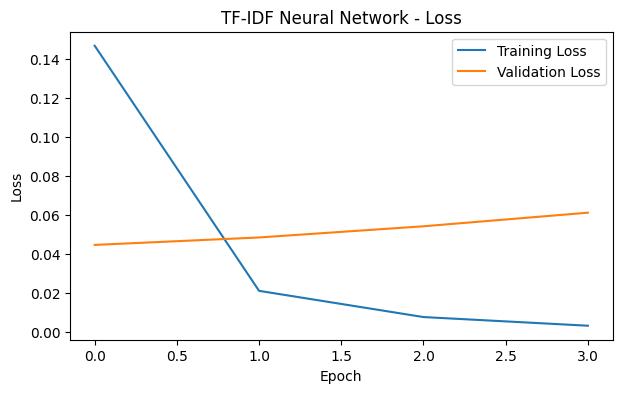

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 4))
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("TF-IDF Neural Network - Loss")
plt.legend()
plt.show()

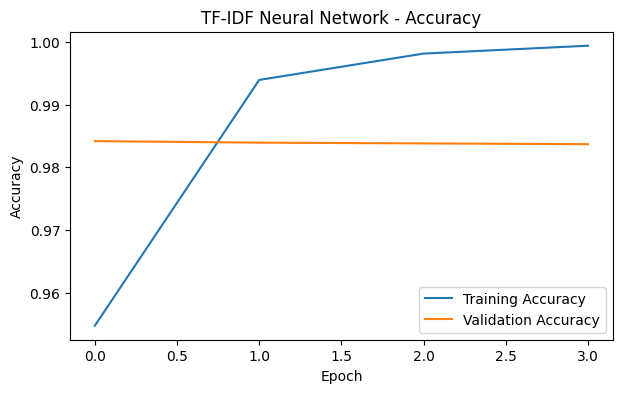

In [ ]:
plt.figure(figsize=(7, 4))
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("TF-IDF Neural Network - Accuracy")
plt.legend()
plt.show()

In [ ]:
val_prob = model.predict(X_val_tf).ravel()
val_pred = (val_prob >= 0.5).astype(int)

print("First 10 probabilities:")
print(val_prob[:10])

print("\nFirst 10 predictions:")
print(val_pred[:10])

257/257 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step
First 10 probabilities:
[0.3381669  0.9559744  0.9686818  0.93231946 0.00323387 0.99995327
 0.00407703 0.0305581  0.04349394 0.9999611 ]

First 10 predictions:
[0 1 1 1 0 1 0 0 0 1]


In [ ]:
scores = evaluate_predictions(
    val_df["label"],
    val_pred,
    val_df["source"]
)

print("Macro-F1:", scores["macro_f1"])
print("Accuracy:", scores["accuracy"])

print("\nPer-class metrics:")
display(scores["per_class"])

print("\nConfusion matrix:")
print(scores["confusion_matrix"])

print("\nPer-domain results:")
display(scores["per_domain"])

Macro-F1: 0.9818737709729907
Accuracy: 0.9841810659527865

Per-class metrics:


,precision,recall,f1,support
class,,,,
human,0.990473,0.986218,0.988341,5587
ai,0.970998,0.979856,0.975407,2631



Confusion matrix:
[[5510   77]
 [  53 2578]]

Per-domain results:


{'finance': {'macro_f1': 0.9916794323727052,
  'accuracy': 0.991715976331361,
  'per_class':        precision    recall        f1  support
  class                                        
  human   0.987374  0.994911  0.991128      393
  ai      0.995546  0.988938  0.992231      452,
  'confusion_matrix': array([[391,   2],
         [  5, 447]])},
 'medicine': {'macro_f1': 0.9960156832865057,
  'accuracy': 0.9960159362549801,
  'per_class':        precision  recall        f1  support
  class                                      
  human   1.000000   0.992  0.995984      125
  ai      0.992126   1.000  0.996047      126,
  'confusion_matrix': array([[124,   1],
         [  0, 126]])},
 'open_qa': {'macro_f1': 0.8856938221035746,
  'accuracy': 0.9129511677282378,
  'per_class':        precision    recall        f1  support
  class                                        
  human   0.819672  0.840336  0.829876      119
  ai      0.945559  0.937500  0.941512      352,
  'confusion_matrix': a

Validation AUC: 0.9983540141136402


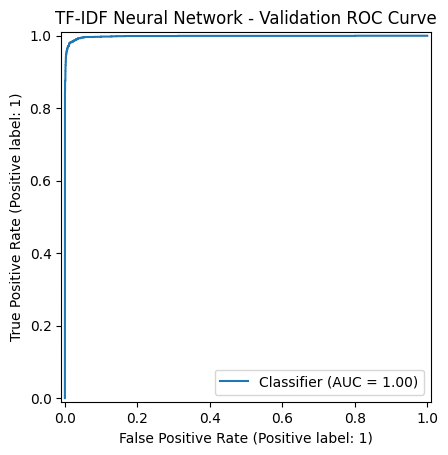

In [ ]:
from sklearn.metrics import roc_auc_score, RocCurveDisplay
import matplotlib.pyplot as plt

val_auc = roc_auc_score(y_val, val_prob)

print("Validation AUC:", val_auc)

RocCurveDisplay.from_predictions(y_val, val_prob)
plt.title("TF-IDF Neural Network - Validation ROC Curve")
plt.show()

In [ ]:
experiment_results = []

experiment_results.append({
    "Experiment": "TF-IDF NN 1",
    "Architecture": "128-64",
    "Dropout": "0.4 / 0.3",
    "Class Weights": "Yes",
    "Macro-F1": scores["macro_f1"],
    "Accuracy": scores["accuracy"],
    "Human Recall": scores["per_class"].loc["human", "recall"],
    "AI Recall": scores["per_class"].loc["ai", "recall"],
    "AUC": val_auc
})

## Experiment 2: TF-IDF Neural Network without Class Weights

In [ ]:
tf.random.set_seed(42)

model_2 = keras.Sequential([
    layers.Input(shape=(20000,), sparse=True),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.4),
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(1, activation="sigmoid")
])

model_2.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

early_stopping_2 = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

In [ ]:
history_2 = model_2.fit(
    X_train_tf,
    y_train,
    validation_data=(X_val_tf, y_val),
    epochs=20,
    batch_size=256,
    callbacks=[early_stopping_2],
    verbose=1
)

Epoch 1/20
256/256 ━━━━━━━━━━━━━━━━━━━━ 12s 36ms/step - accuracy: 0.9431 - loss: 0.1419 - val_accuracy: 0.9845 - val_loss: 0.0422
Epoch 2/20
256/256 ━━━━━━━━━━━━━━━━━━━━ 11s 39ms/step - accuracy: 0.9945 - loss: 0.0188 - val_accuracy: 0.9831 - val_loss: 0.0498
Epoch 3/20
256/256 ━━━━━━━━━━━━━━━━━━━━ 8s 33ms/step - accuracy: 0.9985 - loss: 0.0061 - val_accuracy: 0.9841 - val_loss: 0.0560
Epoch 4/20
256/256 ━━━━━━━━━━━━━━━━━━━━ 8s 33ms/step - accuracy: 0.9996 - loss: 0.0024 - val_accuracy: 0.9841 - val_loss: 0.0613


In [ ]:
val_prob_2 = model_2.predict(X_val_tf).ravel()
val_pred_2 = (val_prob_2 >= 0.5).astype(int)

scores_2 = evaluate_predictions(
    val_df["label"],
    val_pred_2,
    val_df["source"]
)

auc_2 = roc_auc_score(y_val, val_prob_2)

print("Macro-F1:", scores_2["macro_f1"])
print("Accuracy:", scores_2["accuracy"])
print("AUC:", auc_2)

display(scores_2["per_class"])

257/257 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step
Macro-F1: 0.9821828100306474
Accuracy: 0.984546118276953
AUC: 0.9984385073755067


,precision,recall,f1,support
class,,,,
human,0.985420,0.991946,0.988672,5587
ai,0.982652,0.968833,0.975694,2631


In [ ]:
experiment_results.append({
    "Experiment": "TF-IDF NN 2",
    "Architecture": "128-64",
    "Dropout": "0.4 / 0.3",
    "Class Weights": "No",
    "Macro-F1": scores_2["macro_f1"],
    "Accuracy": scores_2["accuracy"],
    "Human Recall": scores_2["per_class"].loc["human", "recall"],
    "AI Recall": scores_2["per_class"].loc["ai", "recall"],
    "AUC": auc_2
})

## Experiment 3: Smaller TF-IDF Neural Network

In [ ]:
tf.random.set_seed(42)

model_3 = keras.Sequential([
    layers.Input(shape=(20000,), sparse=True),

    layers.Dense(64, activation="relu"),
    layers.Dropout(0.4),

    layers.Dense(32, activation="relu"),
    layers.Dropout(0.3),

    layers.Dense(1, activation="sigmoid")
])

model_3.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

early_stopping_3 = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

In [ ]:
history_3 = model_3.fit(
    X_train_tf,
    y_train,
    validation_data=(X_val_tf, y_val),
    epochs=20,
    batch_size=256,
    class_weight=class_weights,
    callbacks=[early_stopping_3],
    verbose=1
)

Epoch 1/20
256/256 ━━━━━━━━━━━━━━━━━━━━ 9s 30ms/step - accuracy: 0.9522 - loss: 0.1884 - val_accuracy: 0.9837 - val_loss: 0.0442
Epoch 2/20
256/256 ━━━━━━━━━━━━━━━━━━━━ 8s 19ms/step - accuracy: 0.9910 - loss: 0.0297 - val_accuracy: 0.9842 - val_loss: 0.0455
Epoch 3/20
256/256 ━━━━━━━━━━━━━━━━━━━━ 5s 21ms/step - accuracy: 0.9966 - loss: 0.0128 - val_accuracy: 0.9841 - val_loss: 0.0514
Epoch 4/20
256/256 ━━━━━━━━━━━━━━━━━━━━ 5s 19ms/step - accuracy: 0.9986 - loss: 0.0062 - val_accuracy: 0.9828 - val_loss: 0.0586


In [ ]:
val_prob_3 = model_3.predict(X_val_tf).ravel()
val_pred_3 = (val_prob_3 >= 0.5).astype(int)

scores_3 = evaluate_predictions(
    val_df["label"],
    val_pred_3,
    val_df["source"]
)

auc_3 = roc_auc_score(y_val, val_prob_3)

print("Macro-F1:", scores_3["macro_f1"])
print("Accuracy:", scores_3["accuracy"])
print("AUC:", auc_3)

display(scores_3["per_class"])

257/257 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step
Macro-F1: 0.9812786610002309
Accuracy: 0.9836943295205646
AUC: 0.9982751673418986


,precision,recall,f1,support
class,,,,
human,0.988358,0.987650,0.988004,5587
ai,0.973814,0.975295,0.974554,2631


In [ ]:
experiment_results.append({
    "Experiment": "TF-IDF NN 3",
    "Architecture": "64-32",
    "Dropout": "0.4 / 0.3",
    "Class Weights": "Yes",
    "Macro-F1": scores_3["macro_f1"],
    "Accuracy": scores_3["accuracy"],
    "Human Recall": scores_3["per_class"].loc["human", "recall"],
    "AI Recall": scores_3["per_class"].loc["ai", "recall"],
    "AUC": auc_3
})

## Experiment Comparison

In [ ]:
import pandas as pd

results_df = pd.DataFrame(experiment_results)
display(results_df)

,Experiment,Architecture,Dropout,Class Weights,Macro-F1,Accuracy,Human Recall,AI Recall,AUC
0,TF-IDF NN 1,128-64,0.4 / 0.3,Yes,0.981874,0.984181,0.986218,0.979856,0.998354
1,TF-IDF NN 2,128-64,0.4 / 0.3,No,0.982183,0.984546,0.991946,0.968833,0.998439
2,TF-IDF NN 3,64-32,0.4 / 0.3,Yes,0.981279,0.983694,0.987650,0.975295,0.998275


## Learned Embedding Neural Network

## Final Test Evaluation